In [19]:
import numpy as np
import pickle
import os
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    Dropout, BatchNormalization, Activation
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

from math import ceil

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [20]:
# Load CIFAR-10 batch file
def load_batch(file):
    with open(file, 'rb') as f:
        data = pickle.load(f, encoding='bytes')

    X = data[b'data']
    y = data[b'labels']

    return X, y


# Load all training batches
X_train = []
y_train = []

for i in range(1, 6):
    X, y = load_batch(f'data_batch_{i}')
    X_train.append(X)
    y_train.extend(y)

X_train = np.concatenate(X_train)
y_train = np.array(y_train)

# Load testing batch
X_test, y_test = load_batch('test_batch')
y_test = np.array(y_test)

# Reshape images into 32x32 RGB format
X_train = X_train.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
X_test = X_test.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

# Normalize images
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0



print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Classes:", class_names)

Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


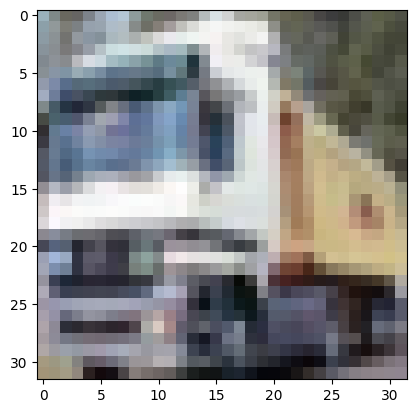

In [21]:
plt.imshow(X_train[1])
plt.show()

In [22]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train)

print("Data Augmentation Applied")

Data Augmentation Applied


In [23]:
def create_model(use_bn=False, use_dropout=False):

    model = Sequential([
        Conv2D(32, (3,3), activation='relu',
               padding='same', input_shape=(32,32,3)),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        Dropout(0.25),

        Conv2D(64, (3,3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    return model

In [ ]:
EPOCHS = 1
BATCH_SIZE = 64

# Model 1: Without BN and Dropout
model1 = create_model(False, False)
model1.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
           epochs=EPOCHS)

# Model 2: With BN
model2 = create_model(True, False)
model2.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
           epochs=EPOCHS)

# Model 3: With Dropout
model3 = create_model(False, True)
model3.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
           epochs=EPOCHS)

# Model 4: With BN and Dropout
model4 = create_model(True, True)
model4.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
           epochs=EPOCHS)



782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.4009 - loss: 1.7176
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.4043 - loss: 1.7336
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.4067 - loss: 1.7216
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.4132 - loss: 1.6975
Accuracy: 45.210000872612
Accuracy: 53.329998254776
Accuracy: 45.32000124454498
Accuracy: 51.31000280380249


In [28]:
print("\nMODEL COMPARISON")

for name, accuracy in results.items():
    print(name, ":", round(accuracy * 100, 2), "%")


MODEL COMPARISON
Without BN and Dropout : 46.37 %
With BN : 52.35 %
With Dropout : 50.21 %
With BN and Dropout : 40.11 %


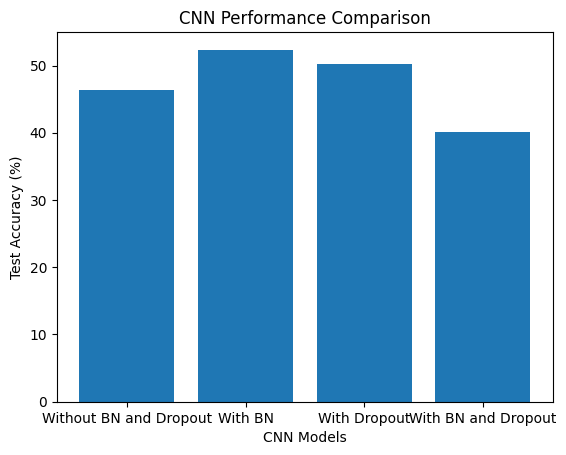

In [33]:


plt.bar(results.keys(),
        [v * 100 for v in results.values()])

plt.ylabel("Test Accuracy (%)")
plt.xlabel("CNN Models")
plt.title("CNN Performance Comparison")
plt.show()